In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd 

In [21]:
r2010 = pd.read_csv("../../data/processed/results2010.csv")
r2010.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2432 entries, 0 to 2431
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             2432 non-null   int64  
 1   entidad                2432 non-null   int64  
 2   nom_ent                2432 non-null   object 
 3   mun                    2432 non-null   int64  
 4   nom_mun                2432 non-null   object 
 5   loc                    2432 non-null   int64  
 6   nom_loc                2432 non-null   object 
 7   ageb                   2432 non-null   object 
 8   mza                    2432 non-null   int64  
 9   pobtot                 2432 non-null   int64  
 10  p_60ymas               2420 non-null   float64
 11  cvegeo                 2432 non-null   object 
 12  cantidad_serv_enf_dom  2432 non-null   float64
 13  cantidad_asilos        2432 non-null   float64
 14  p_60ymas_mun           2432 non-null   float64
 15  conc

In [22]:
datos2010 = r2010[["cvegeo", "p_60ymas", "cantidad_serv_enf_dom", "cantidad_asilos"]]
datos2010.sample()

,cvegeo,p_60ymas,cantidad_serv_enf_dom,cantidad_asilos
2340,0901700010600,293.0,0.0,0.0


In [23]:
r2015 = pd.read_csv("../../data/processed/results2015.csv")
r2015.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2433 entries, 0 to 2432
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             2433 non-null   int64  
 1   entidad                2433 non-null   int64  
 2   nom_ent                2433 non-null   object 
 3   mun                    2433 non-null   int64  
 4   nom_mun                2433 non-null   object 
 5   loc                    2433 non-null   int64  
 6   nom_loc                2433 non-null   object 
 7   ageb                   2433 non-null   object 
 8   cvegeo                 2433 non-null   object 
 9   p_60ymas_est           2428 non-null   float64
 10  cantidad_serv_enf_dom  2433 non-null   float64
 11  cantidad_asilos        2433 non-null   float64
dtypes: float64(3), int64(4), object(5)
memory usage: 228.2+ KB


In [24]:
datos2015 = r2015[["cvegeo", "p_60ymas_est", "cantidad_serv_enf_dom", "cantidad_asilos"]]
datos2015.sample()

,cvegeo,p_60ymas_est,cantidad_serv_enf_dom,cantidad_asilos
870,0900700012206,254.029423,0.0,0.0


In [25]:
r2020 = pd.read_csv("../../data/processed/results2020.csv")
r2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2433 entries, 0 to 2432
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             2433 non-null   int64  
 1   entidad                2433 non-null   int64  
 2   nom_ent                2433 non-null   object 
 3   mun                    2433 non-null   int64  
 4   nom_mun                2433 non-null   object 
 5   loc                    2433 non-null   int64  
 6   nom_loc                2433 non-null   object 
 7   ageb                   2433 non-null   object 
 8   mza                    2433 non-null   int64  
 9   pobtot                 2433 non-null   int64  
 10  p_60ymas               2416 non-null   float64
 11  cvegeo                 2433 non-null   object 
 12  cantidad_serv_enf_dom  2433 non-null   float64
 13  cantidad_asilos        2433 non-null   float64
 14  p_60ymas_mun           2433 non-null   float64
 15  conc

In [26]:
datos2020 = r2020[["cvegeo", "p_60ymas", "cantidad_serv_enf_dom", "cantidad_asilos"]]
datos2020.sample()

,cvegeo,p_60ymas,cantidad_serv_enf_dom,cantidad_asilos
1965,090140001069A,334.0,0.0,0.0


In [27]:
ageb = gpd.read_file('../../assets/2020_1_09_A.shp')
ageb.columns

Index(['CVEGEO', 'CVE_ENT', 'CVE_MUN', 'CVE_LOC', 'CVE_AGEB', 'geometry'], dtype='object')

In [28]:
ageb.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2431 entries, 0 to 2430
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   CVEGEO    2431 non-null   object  
 1   CVE_ENT   2431 non-null   object  
 2   CVE_MUN   2431 non-null   object  
 3   CVE_LOC   2431 non-null   object  
 4   CVE_AGEB  2431 non-null   object  
 5   geometry  2431 non-null   geometry
dtypes: geometry(1), object(5)
memory usage: 114.1+ KB


In [29]:
mapa2010 = ageb.merge(
    datos2010,
    left_on="CVEGEO", 
    right_on="cvegeo",
    how="left",
    validate="one_to_one",
    indicator=True
)

In [30]:
print(mapa2010["_merge"].value_counts())

_merge
both          2430
left_only        1
right_only       0
Name: count, dtype: int64


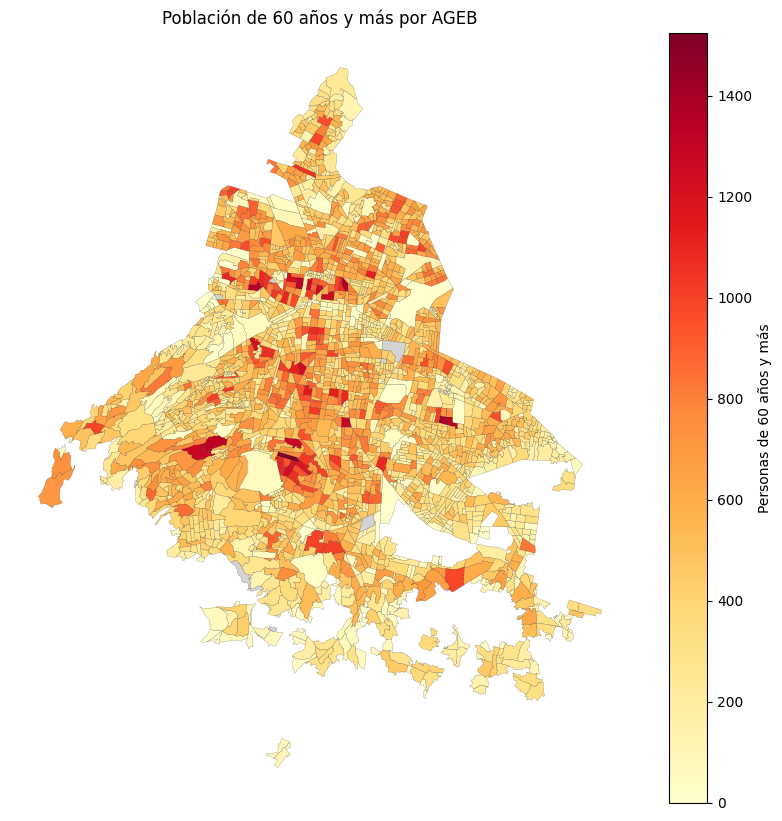

In [31]:

fig, ax = plt.subplots(figsize=(10, 10))

mapa2010.plot(
    column="p_60ymas",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    linewidth=0.1,
    edgecolor="black",
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Sin datos"
    },
    legend_kwds={"label": "Personas de 60 años y más"}
)

ax.set_title("Población de 60 años y más por AGEB")
ax.set_axis_off()
plt.show()

In [32]:
mapa2015 = ageb.merge(
    datos2015,
    left_on="CVEGEO", 
    right_on="cvegeo",
    how="left",
    validate="one_to_one",
    indicator=True
)

In [33]:
print(mapa2015["_merge"].value_counts())

_merge
both          2431
left_only        0
right_only       0
Name: count, dtype: int64


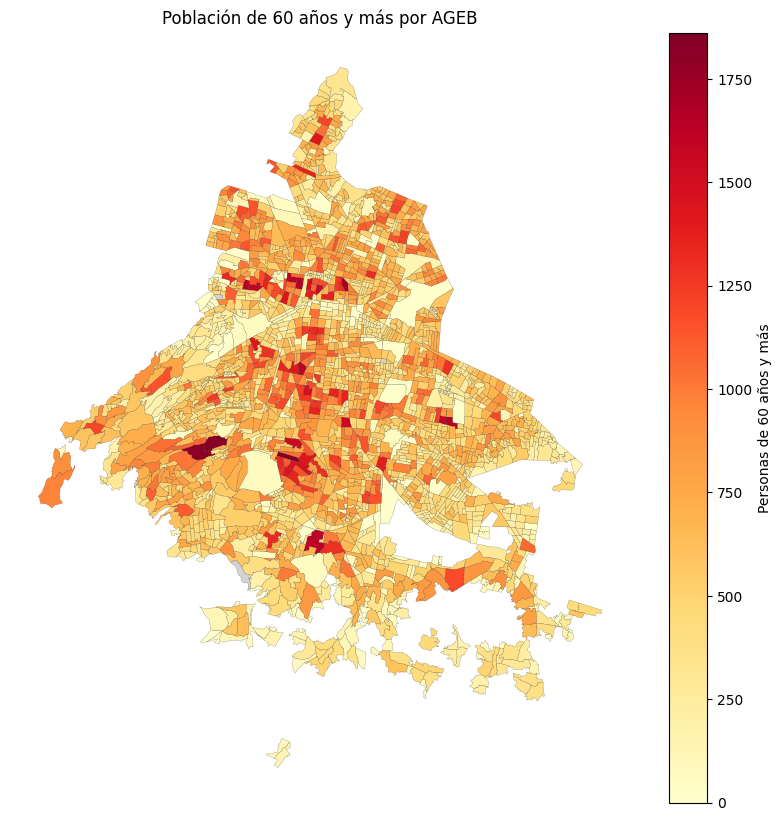

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))

mapa2015.plot(
    column="p_60ymas_est",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    linewidth=0.1,
    edgecolor="black",
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Sin datos"
    },
    legend_kwds={"label": "Personas de 60 años y más"}
)

ax.set_title("Población de 60 años y más por AGEB")
ax.set_axis_off()
plt.show()

In [35]:
mapa2020 = ageb.merge(
    datos2020,
    left_on="CVEGEO", 
    right_on="cvegeo",
    how="left",
    validate="one_to_one",
    indicator=True
)

In [36]:
print(mapa2020["_merge"].value_counts())

_merge
both          2431
left_only        0
right_only       0
Name: count, dtype: int64


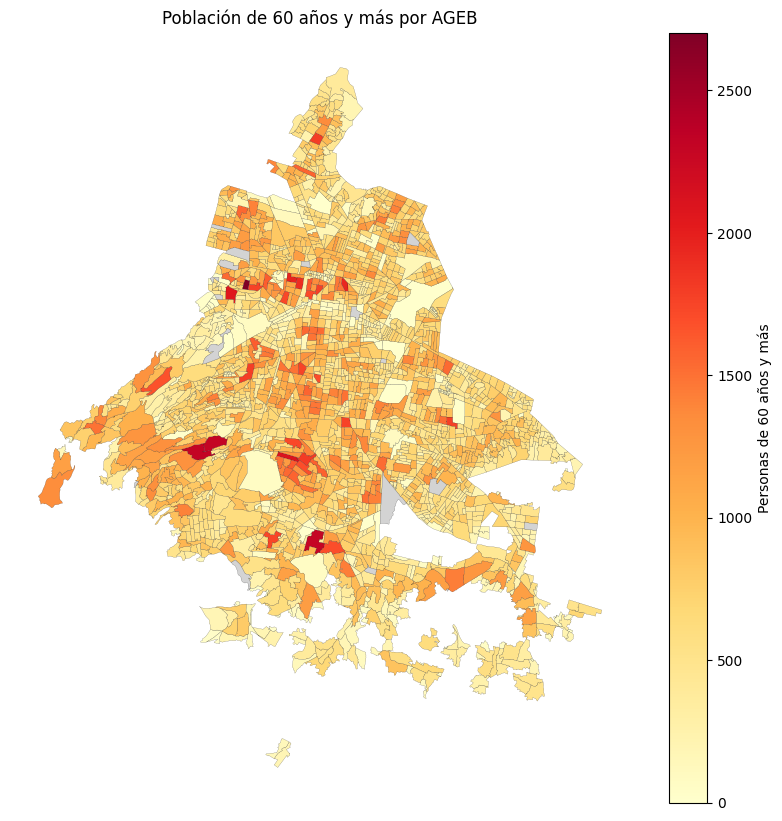

In [37]:
fig, ax = plt.subplots(figsize=(10, 10))

mapa2020.plot(
    column="p_60ymas",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    linewidth=0.1,
    edgecolor="black",
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Sin datos"
    },
    legend_kwds={"label": "Personas de 60 años y más"}
)

ax.set_title("Población de 60 años y más por AGEB")
ax.set_axis_off()
plt.show()